In [77]:
import os
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

BASE_PATH = "/content/credit_card_project"
CHART_PATH = os.path.join(BASE_PATH, "visualizations")
REPORT_PATH = os.path.join(BASE_PATH, "reports")
DATA_PATH = os.path.join(BASE_PATH, "data")

os.makedirs(CHART_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)

print("Project folders created successfully.")

Project folders created successfully.


In [78]:
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Total missing values:", df.isnull().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["ID"].duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

display(df.head())

DATASET OVERVIEW
Rows: 30000
Columns: 25
Total missing values: 0
Exact duplicate rows: 0
Duplicate customer IDs: 0

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Data types:
int64    25
Name: count, dtype: int64


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [79]:
summary_statistics = df.describe().T
display(summary_statistics)

summary_statistics.to_csv(
    os.path.join(REPORT_PATH, "summary_statistics.csv")
)

print("Summary statistics saved.")

,count,mean,std,min,25%,50%,75%,max
ID,"30,000.00","15,000.50","8,660.40",1.00,"7,500.75","15,000.50","22,500.25","30,000.00"
LIMIT_BAL,"30,000.00","167,484.32","129,747.66","10,000.00","50,000.00","140,000.00","240,000.00","1,000,000.00"
SEX,"30,000.00",1.60,0.49,1.00,1.00,2.00,2.00,2.00
EDUCATION,"30,000.00",1.85,0.79,0.00,1.00,2.00,2.00,6.00
MARRIAGE,"30,000.00",1.55,0.52,0.00,1.00,2.00,2.00,3.00
AGE,"30,000.00",35.49,9.22,21.00,28.00,34.00,41.00,79.00
PAY_0,"30,000.00",-0.02,1.12,-2.00,-1.00,0.00,0.00,8.00
PAY_2,"30,000.00",-0.13,1.20,-2.00,-1.00,0.00,0.00,8.00
PAY_3,"30,000.00",-0.17,1.20,-2.00,-1.00,0.00,0.00,8.00
PAY_4,"30,000.00",-0.22,1.17,-2.00,-1.00,0.00,0.00,8.00


Summary statistics saved.


In [80]:
missing_report = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (
        df.isnull().mean() * 100
    ).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_report)

missing_report.to_csv(
    os.path.join(REPORT_PATH, "missing_value_report.csv")
)

,missing_count,missing_percentage
ID,0,0.00
LIMIT_BAL,0,0.00
SEX,0,0.00
EDUCATION,0,0.00
MARRIAGE,0,0.00
AGE,0,0.00
PAY_0,0,0.00
PAY_2,0,0.00
PAY_3,0,0.00
PAY_4,0,0.00


In [81]:
target_column = "default payment next month"

target_count = df[target_column].value_counts().sort_index()

target_percentage = (
    df[target_column]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    "customer_count": target_count,
    "percentage": target_percentage
})

target_summary.index = ["No Default", "Default"]

display(target_summary)

target_summary.to_csv(
    os.path.join(REPORT_PATH, "target_distribution.csv")
)

,customer_count,percentage
No Default,23364,77.88
Default,6636,22.12


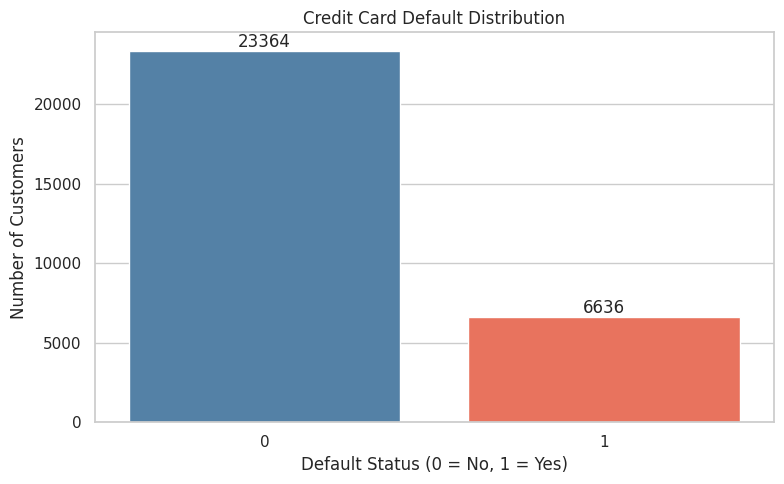

In [82]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=target_column,
    palette=["steelblue", "tomato"]
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "01_default_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [83]:
categorical_columns = ["SEX", "EDUCATION", "MARRIAGE"]

for column in categorical_columns:
    print(f"\nDistribution of {column}")
    print(df[column].value_counts().sort_index())


Distribution of SEX
SEX
1    11888
2    18112
Name: count, dtype: int64

Distribution of EDUCATION
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Distribution of MARRIAGE
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [84]:
for column in categorical_columns:
    result = (
        df.groupby(column)[target_column]
        .agg(
            total_customers="count",
            default_customers="sum",
            default_rate="mean"
        )
    )

    result["default_rate"] = (
        result["default_rate"] * 100
    ).round(2)

    print(f"\nDefault analysis by {column}")
    display(result)

    result.to_csv(
        os.path.join(
            REPORT_PATH,
            f"default_analysis_by_{column.lower()}.csv"
        )
    )


Default analysis by SEX


,total_customers,default_customers,default_rate
SEX,,,
1,11888,2873,24.17
2,18112,3763,20.78



Default analysis by EDUCATION


,total_customers,default_customers,default_rate
EDUCATION,,,
0,14,0,0.00
1,10585,2036,19.23
2,14030,3330,23.73
3,4917,1237,25.16
4,123,7,5.69
5,280,18,6.43
6,51,8,15.69



Default analysis by MARRIAGE


,total_customers,default_customers,default_rate
MARRIAGE,,,
0,54,5,9.26
1,13659,3206,23.47
2,15964,3341,20.93
3,323,84,26.01


In [85]:
for column in categorical_columns:
    result = (
        df.groupby(column)[target_column]
        .agg(
            total_customers="count",
            default_customers="sum",
            default_rate="mean"
        )
    )

    result["default_rate"] = (
        result["default_rate"] * 100
    ).round(2)

    print(f"\nDefault analysis by {column}")
    display(result)

    result.to_csv(
        os.path.join(
            REPORT_PATH,
            f"default_analysis_by_{column.lower()}.csv"
        )
    )


Default analysis by SEX


,total_customers,default_customers,default_rate
SEX,,,
1,11888,2873,24.17
2,18112,3763,20.78



Default analysis by EDUCATION


,total_customers,default_customers,default_rate
EDUCATION,,,
0,14,0,0.00
1,10585,2036,19.23
2,14030,3330,23.73
3,4917,1237,25.16
4,123,7,5.69
5,280,18,6.43
6,51,8,15.69



Default analysis by MARRIAGE


,total_customers,default_customers,default_rate
MARRIAGE,,,
0,54,5,9.26
1,13659,3206,23.47
2,15964,3341,20.93
3,323,84,26.01


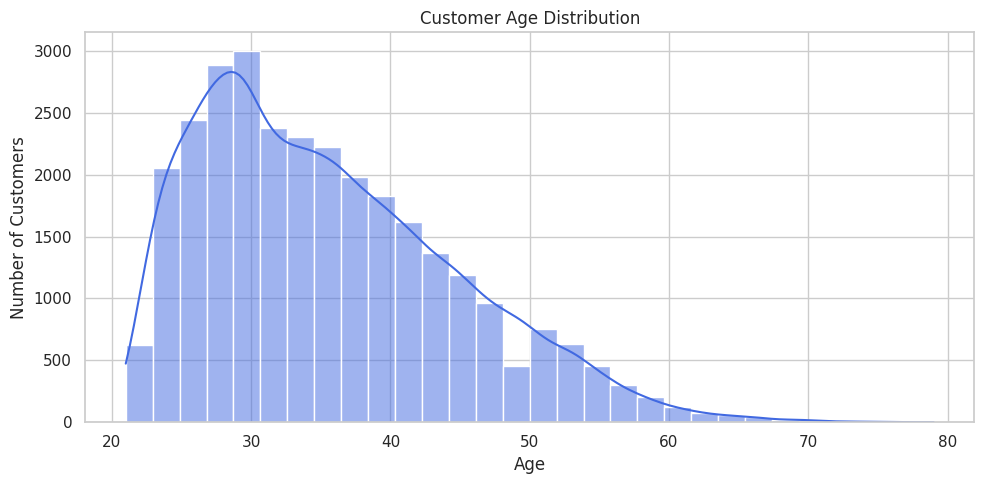

In [86]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="AGE",
    bins=30,
    kde=True,
    color="royalblue"
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "02_age_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

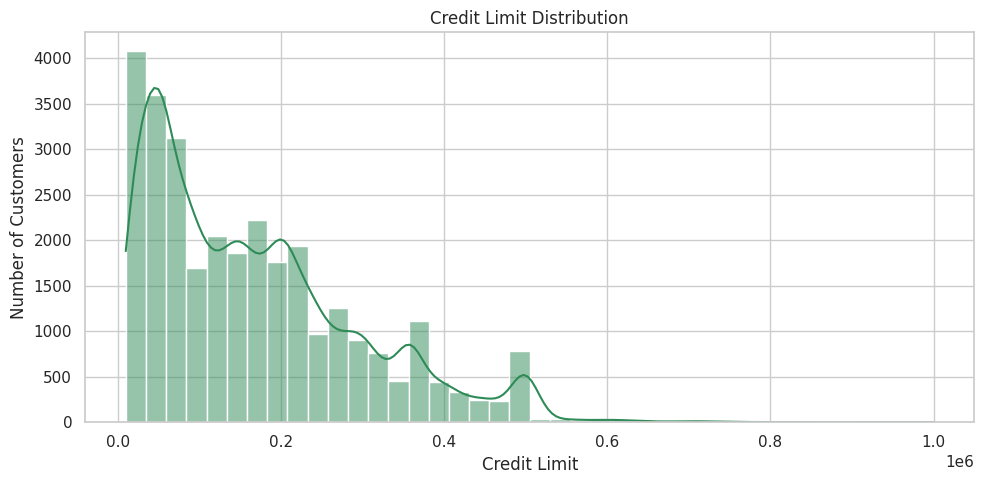

In [87]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="LIMIT_BAL",
    bins=40,
    kde=True,
    color="seagreen"
)

plt.title("Credit Limit Distribution")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "03_credit_limit_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

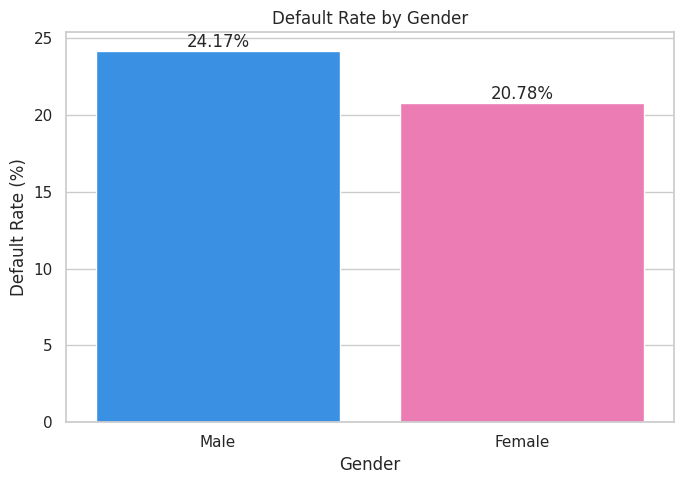

In [88]:
gender_default = (
    df.groupby("SEX")[target_column]
    .mean()
    .mul(100)
    .reset_index(name="default_rate")
)

gender_default["gender"] = gender_default["SEX"].map({
    1: "Male",
    2: "Female"
})

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=gender_default,
    x="gender",
    y="default_rate",
    palette=["dodgerblue", "hotpink"]
)

plt.title("Default Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "04_default_rate_by_gender.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

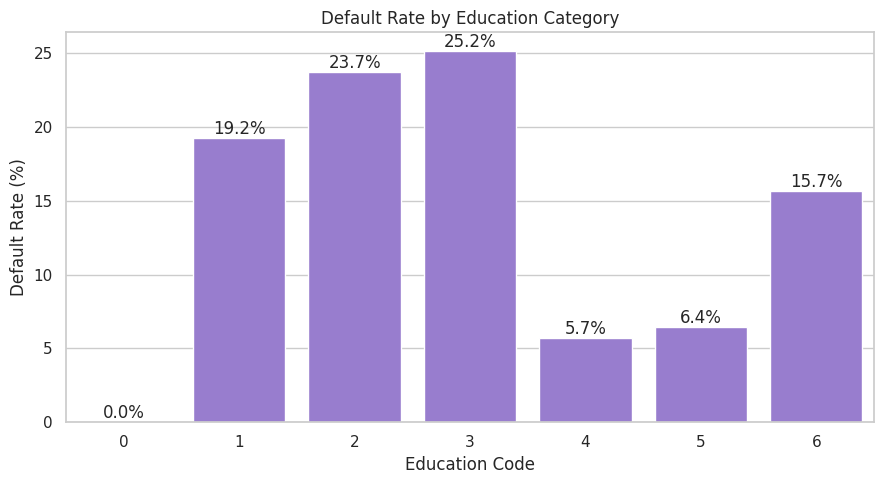

In [89]:
education_default = (
    df.groupby("EDUCATION")[target_column]
    .mean()
    .mul(100)
    .reset_index(name="default_rate")
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=education_default,
    x="EDUCATION",
    y="default_rate",
    color="mediumpurple"
)

plt.title("Default Rate by Education Category")
plt.xlabel("Education Code")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "05_default_rate_by_education.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

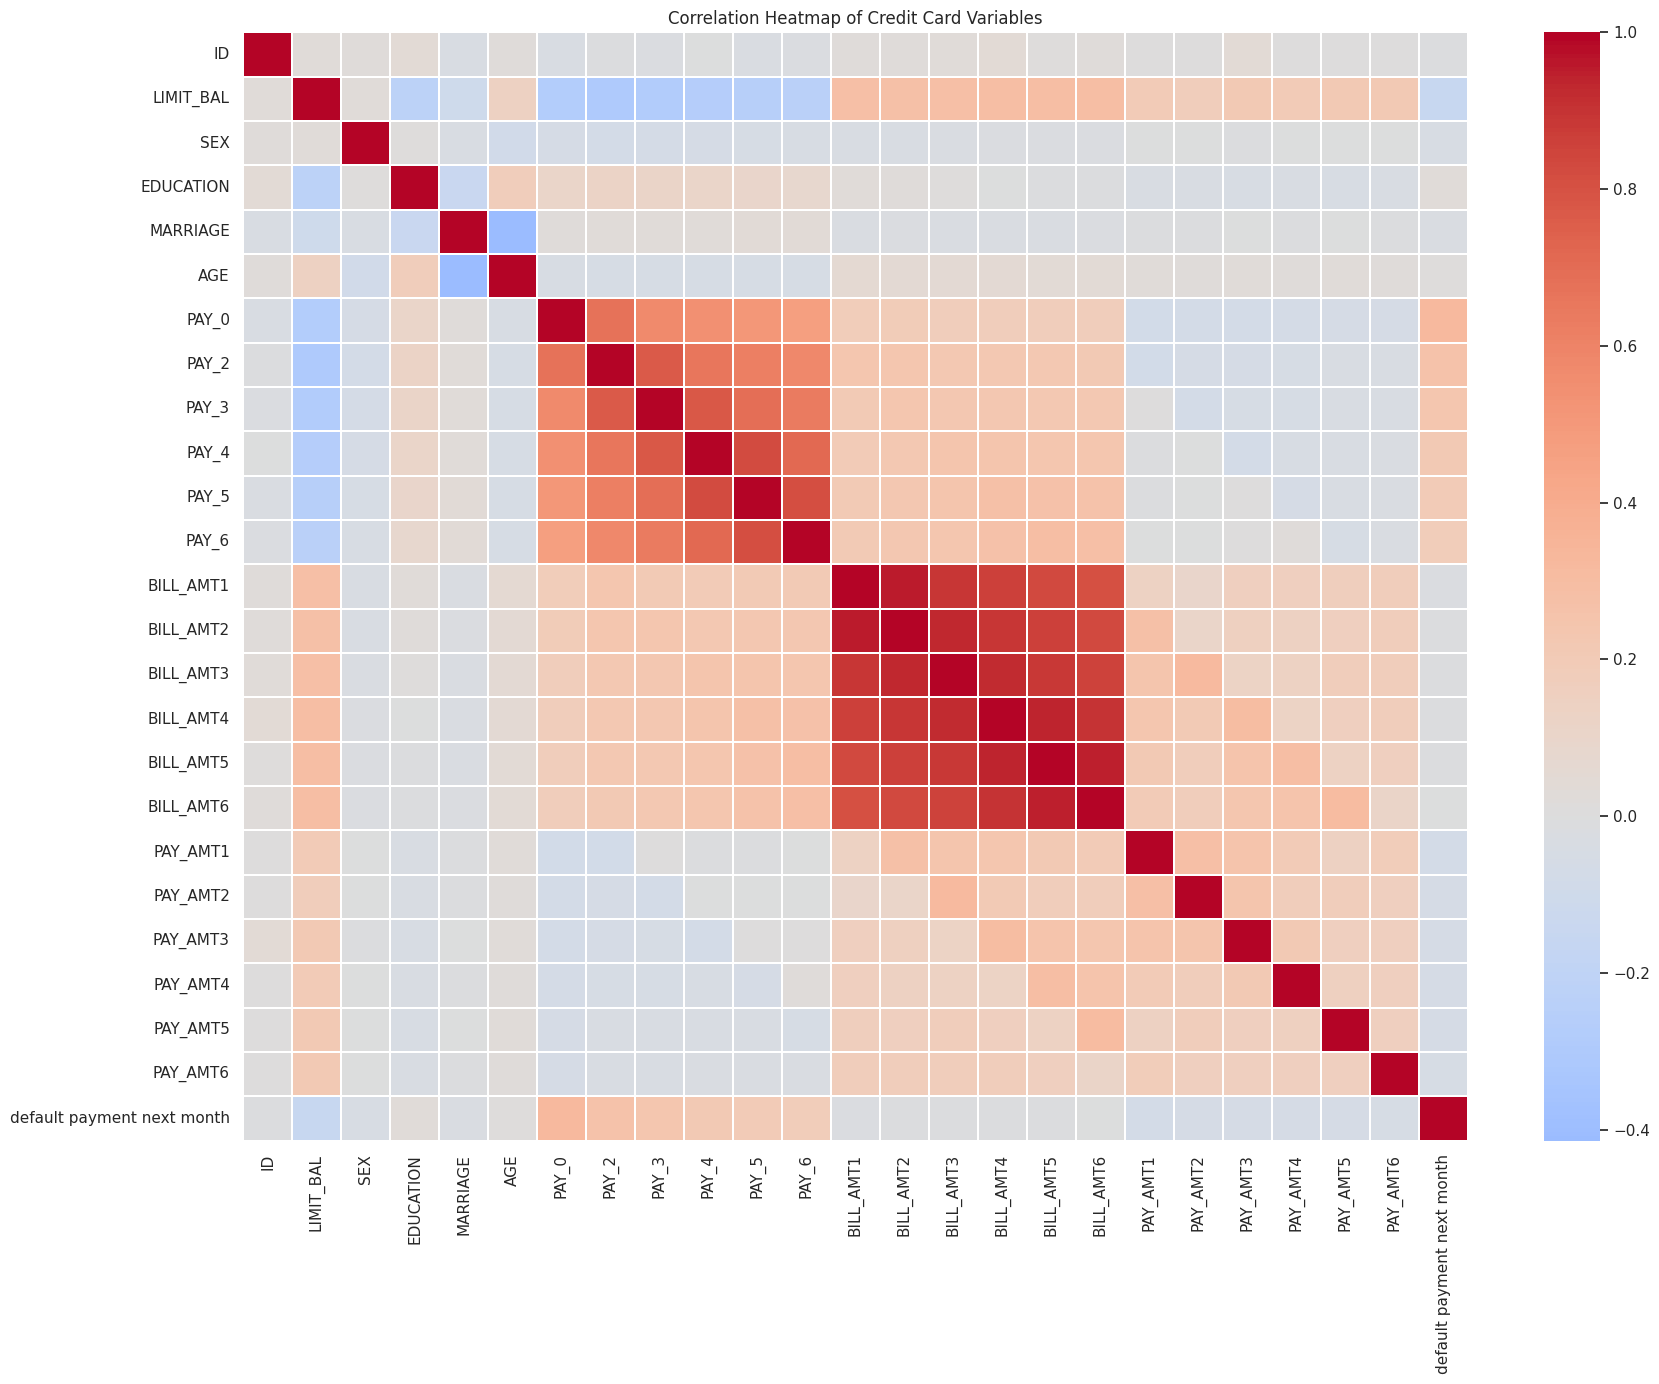

In [90]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of Credit Card Variables")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "06_correlation_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [91]:
target_correlation = (
    correlation_matrix[target_column]
    .drop(target_column)
    .sort_values(ascending=False)
)

display(target_correlation.to_frame("correlation_with_default"))

target_correlation.to_csv(
    os.path.join(REPORT_PATH, "target_correlations.csv")
)

,correlation_with_default
PAY_0,0.32
PAY_2,0.26
PAY_3,0.24
PAY_4,0.22
PAY_5,0.20
PAY_6,0.19
EDUCATION,0.03
AGE,0.01
BILL_AMT6,-0.01
BILL_AMT5,-0.01


In [92]:
clean_df = df.copy()

clean_df.rename(
    columns={
        "default payment next month": "default_status"
    },
    inplace=True
)

print("Cleaning copy created.")
print(clean_df.shape)

Cleaning copy created.
(30000, 25)


In [93]:
rows_before = len(clean_df)

clean_df.drop_duplicates(inplace=True)

rows_after = len(clean_df)

print("Rows before duplicate removal:", rows_before)
print("Rows after duplicate removal:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before duplicate removal: 30000
Rows after duplicate removal: 30000
Rows removed: 0


In [94]:
print("Education before cleaning:")
print(clean_df["EDUCATION"].value_counts().sort_index())

clean_df["EDUCATION"] = clean_df["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4
})

print("\nEducation after cleaning:")
print(clean_df["EDUCATION"].value_counts().sort_index())

Education before cleaning:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Education after cleaning:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64


In [95]:
print("Marriage before cleaning:")
print(clean_df["MARRIAGE"].value_counts().sort_index())

clean_df["MARRIAGE"] = clean_df["MARRIAGE"].replace({
    0: 3
})

print("\nMarriage after cleaning:")
print(clean_df["MARRIAGE"].value_counts().sort_index())

Marriage before cleaning:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Marriage after cleaning:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [96]:
validation_report = {
    "invalid_sex": (
        ~clean_df["SEX"].isin([1, 2])
    ).sum(),

    "invalid_education": (
        ~clean_df["EDUCATION"].isin([1, 2, 3, 4])
    ).sum(),

    "invalid_marriage": (
        ~clean_df["MARRIAGE"].isin([1, 2, 3])
    ).sum(),

    "invalid_age": (
        (clean_df["AGE"] < 18) |
        (clean_df["AGE"] > 100)
    ).sum(),

    "invalid_credit_limit": (
        clean_df["LIMIT_BAL"] <= 0
    ).sum(),

    "invalid_target": (
        ~clean_df["default_status"].isin([0, 1])
    ).sum()
}

validation_df = pd.DataFrame(
    validation_report.items(),
    columns=["validation_check", "invalid_records"]
)

display(validation_df)

validation_df.to_csv(
    os.path.join(REPORT_PATH, "validation_report.csv"),
    index=False
)

,validation_check,invalid_records
0,invalid_sex,0
1,invalid_education,0
2,invalid_marriage,0
3,invalid_age,0
4,invalid_credit_limit,0
5,invalid_target,0


In [75]:
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Total missing values:", df.isnull().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["ID"].duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

display(df.head())

DATASET OVERVIEW
Rows: 30000
Columns: 25
Total missing values: 0
Exact duplicate rows: 0
Duplicate customer IDs: 0

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Data types:
int64    25
Name: count, dtype: int64


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [97]:
outlier_columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

outlier_report = []

for column in outlier_columns:
    q1 = clean_df[column].quantile(0.25)
    q3 = clean_df[column].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - (1.5 * iqr)
    upper_limit = q3 + (1.5 * iqr)

    flag_column = f"{column.lower()}_outlier"

    clean_df[flag_column] = (
        (clean_df[column] < lower_limit) |
        (clean_df[column] > upper_limit)
    ).astype(int)

    outlier_report.append({
        "column": column,
        "lower_limit": lower_limit,
        "upper_limit": upper_limit,
        "outlier_count": clean_df[flag_column].sum()
    })

outlier_report_df = pd.DataFrame(outlier_report)

display(outlier_report_df)

outlier_report_df.to_csv(
    os.path.join(REPORT_PATH, "outlier_report.csv"),
    index=False
)

,column,lower_limit,upper_limit,outlier_count
0,LIMIT_BAL,"-235,000.00","525,000.00",167
1,AGE,8.50,60.50,272
2,BILL_AMT1,"-91,739.62","162,389.38",2400
3,BILL_AMT2,"-88,547.50","155,538.50",2395
4,BILL_AMT3,"-83,581.50","146,412.50",2469
5,BILL_AMT4,"-75,942.12","132,774.88",2622
6,BILL_AMT5,"-70,878.25","122,831.75",2725
7,BILL_AMT6,"-70,657.38","121,111.62",2693
8,PAY_AMT1,"-5,009.00","11,015.00",2745
9,PAY_AMT2,"-5,417.50","11,250.50",2714


In [98]:
print("=" * 60)
print("CLEANING SUMMARY")
print("=" * 60)

print("Final rows:", clean_df.shape[0])
print("Final columns:", clean_df.shape[1])
print("Missing values:", clean_df.isnull().sum().sum())
print("Exact duplicates:", clean_df.duplicated().sum())
print("Duplicate IDs:", clean_df["ID"].duplicated().sum())

CLEANING SUMMARY
Final rows: 30000
Final columns: 39
Missing values: 0
Exact duplicates: 0
Duplicate IDs: 0


In [99]:
processed_df = clean_df.copy()

processed_df["gender"] = processed_df["SEX"].map({
    1: "Male",
    2: "Female"
})

processed_df["education_level"] = processed_df["EDUCATION"].map({
    1: "Graduate School",
    2: "University",
    3: "High School",
    4: "Others"
})

processed_df["marital_status"] = processed_df["MARRIAGE"].map({
    1: "Married",
    2: "Single",
    3: "Others"
})

processed_df["default_label"] = processed_df["default_status"].map({
    0: "No Default",
    1: "Default"
})

display(
    processed_df[
        [
            "SEX",
            "gender",
            "EDUCATION",
            "education_level",
            "MARRIAGE",
            "marital_status",
            "default_status",
            "default_label"
        ]
    ].head()
)

,SEX,gender,EDUCATION,education_level,MARRIAGE,marital_status,default_status,default_label
0,2,Female,2,University,1,Married,1,Default
1,2,Female,2,University,2,Single,1,Default
2,2,Female,2,University,2,Single,0,No Default
3,2,Female,2,University,1,Married,0,No Default
4,1,Male,2,University,1,Married,0,No Default


In [100]:
processed_df["age_group"] = pd.cut(
    processed_df["AGE"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ]
)

print(processed_df["age_group"].value_counts().sort_index())

age_group
18-25     3871
26-35    12938
36-45     8522
46-55     3825
56-65      758
65+         86
Name: count, dtype: int64


In [101]:
age_group_analysis = (
    processed_df.groupby(
        "age_group",
        observed=False
    )
    .agg(
        total_customers=("ID", "count"),
        default_customers=("default_status", "sum"),
        default_rate=("default_status", "mean")
    )
    .reset_index()
)

age_group_analysis["default_rate"] = (
    age_group_analysis["default_rate"] * 100
).round(2)

display(age_group_analysis)

age_group_analysis.to_csv(
    os.path.join(REPORT_PATH, "age_group_analysis.csv"),
    index=False
)

,age_group,total_customers,default_customers,default_rate
0,18-25,3871,1032,26.66
1,26-35,12938,2565,19.83
2,36-45,8522,1861,21.84
3,46-55,3825,954,24.94
4,56-65,758,201,26.52
5,65+,86,23,26.74


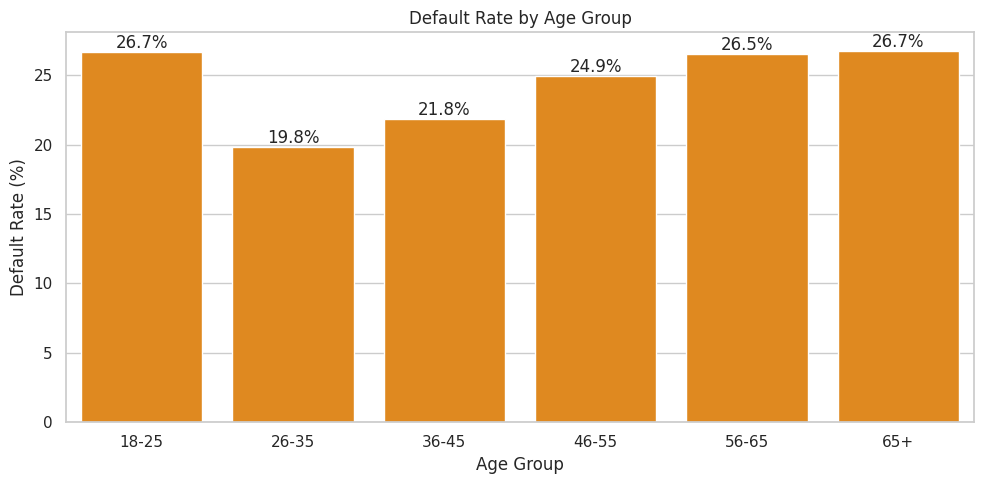

In [102]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=age_group_analysis,
    x="age_group",
    y="default_rate",
    color="darkorange"
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "07_default_rate_by_age_group.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [103]:
repayment_columns = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

bill_columns = [
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6"
]

payment_columns = [
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

In [104]:
processed_df["average_bill_amount"] = (
    processed_df[bill_columns].mean(axis=1)
)

processed_df["total_bill_amount"] = (
    processed_df[bill_columns].sum(axis=1)
)

processed_df["average_payment_amount"] = (
    processed_df[payment_columns].mean(axis=1)
)

processed_df["total_payment_amount"] = (
    processed_df[payment_columns].sum(axis=1)
)

processed_df["bill_to_limit_ratio"] = (
    processed_df["average_bill_amount"] /
    processed_df["LIMIT_BAL"].replace(0, np.nan)
)

processed_df["payment_to_bill_ratio"] = (
    processed_df["total_payment_amount"] /
    processed_df["total_bill_amount"].replace(0, np.nan)
)

processed_df[
    [
        "bill_to_limit_ratio",
        "payment_to_bill_ratio"
    ]
] = processed_df[
    [
        "bill_to_limit_ratio",
        "payment_to_bill_ratio"
    ]
].replace([np.inf, -np.inf], np.nan).fillna(0)

In [105]:
processed_df["delayed_months_count"] = (
    processed_df[repayment_columns] > 0
).sum(axis=1)

processed_df["maximum_delay_months"] = (
    processed_df[repayment_columns].max(axis=1)
)

processed_df["average_repayment_status"] = (
    processed_df[repayment_columns].mean(axis=1)
)

processed_df["has_payment_delay"] = (
    processed_df["delayed_months_count"] > 0
).astype(int)

In [106]:
processed_df["credit_limit_group"] = pd.cut(
    processed_df["LIMIT_BAL"],
    bins=[
        -np.inf,
        50000,
        100000,
        200000,
        500000,
        np.inf
    ],
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

print(
    processed_df["credit_limit_group"]
    .value_counts()
    .sort_index()
)

credit_limit_group
Very Low     7676
Low          4822
Medium       7880
High         9416
Very High     206
Name: count, dtype: int64


In [107]:
conditions = [
    (
        processed_df["delayed_months_count"] >= 3
    ) |
    (
        processed_df["bill_to_limit_ratio"] > 0.90
    ),

    (
        processed_df["delayed_months_count"].between(1, 2)
    ) |
    (
        processed_df["bill_to_limit_ratio"].between(
            0.60,
            0.90,
            inclusive="right"
        )
    )
]

choices = ["High Risk", "Medium Risk"]

processed_df["risk_segment"] = np.select(
    conditions,
    choices,
    default="Low Risk"
)

print(processed_df["risk_segment"].value_counts())

risk_segment
Low Risk       14615
Medium Risk     9654
High Risk       5731
Name: count, dtype: int64


In [108]:
risk_analysis = (
    processed_df.groupby("risk_segment")
    .agg(
        total_customers=("ID", "count"),
        default_customers=("default_status", "sum"),
        default_rate=("default_status", "mean"),
        average_credit_limit=("LIMIT_BAL", "mean"),
        average_delayed_months=("delayed_months_count", "mean")
    )
    .reset_index()
)

risk_analysis["default_rate"] = (
    risk_analysis["default_rate"] * 100
).round(2)

display(risk_analysis)

risk_analysis.to_csv(
    os.path.join(REPORT_PATH, "risk_segment_analysis.csv"),
    index=False
)

,risk_segment,total_customers,default_customers,default_rate,average_credit_limit,average_delayed_months
0,High Risk,5731,2690,46.94,"97,695.63",3.09
1,Low Risk,14615,1592,10.89,"210,166.27",0.00
2,Medium Risk,9654,2354,24.38,"144,298.32",0.76


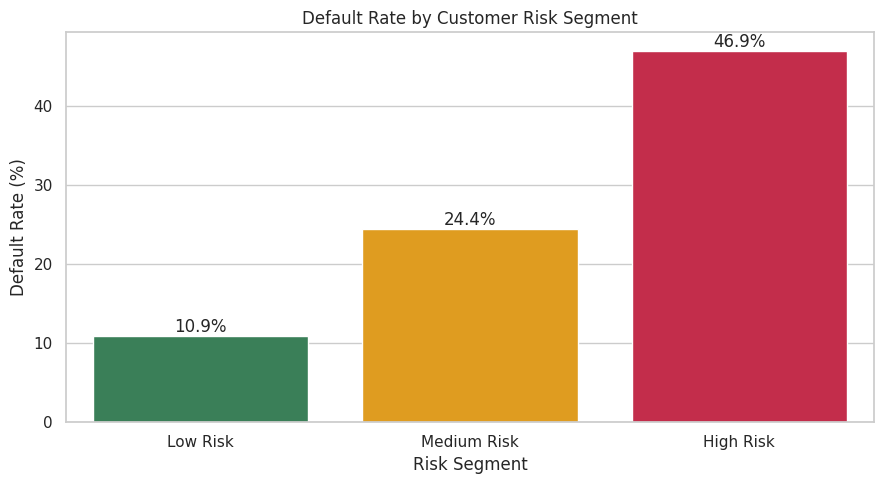

In [109]:
risk_order = ["Low Risk", "Medium Risk", "High Risk"]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=risk_analysis,
    x="risk_segment",
    y="default_rate",
    order=risk_order,
    palette=["seagreen", "orange", "crimson"]
)

plt.title("Default Rate by Customer Risk Segment")
plt.xlabel("Risk Segment")
plt.ylabel("Default Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "08_default_rate_by_risk_segment.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

,delayed_months_count,total_customers,default_customers,default_rate
0,0,19931,2334,11.71
1,1,4426,1320,29.82
2,2,1899,736,38.76
3,3,1154,587,50.87
4,4,951,545,57.31
5,5,298,171,57.38
6,6,1341,943,70.32


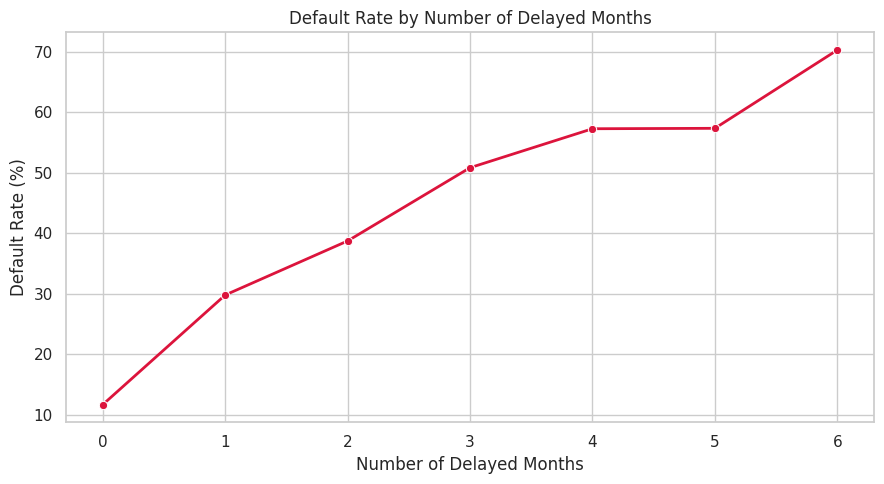

In [110]:
delay_analysis = (
    processed_df.groupby("delayed_months_count")
    .agg(
        total_customers=("ID", "count"),
        default_customers=("default_status", "sum"),
        default_rate=("default_status", "mean")
    )
    .reset_index()
)

delay_analysis["default_rate"] = (
    delay_analysis["default_rate"] * 100
).round(2)

display(delay_analysis)

plt.figure(figsize=(9, 5))

ax = sns.lineplot(
    data=delay_analysis,
    x="delayed_months_count",
    y="default_rate",
    marker="o",
    linewidth=2,
    color="crimson"
)

plt.title("Default Rate by Number of Delayed Months")
plt.xlabel("Number of Delayed Months")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.savefig(
    os.path.join(CHART_PATH, "09_default_rate_by_delayed_months.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [111]:
final_csv_path = os.path.join(
    DATA_PATH,
    "credit_card_default_analysis_ready.csv"
)

final_excel_path = os.path.join(
    DATA_PATH,
    "credit_card_default_analysis_ready.xlsx"
)

processed_df.to_csv(
    final_csv_path,
    index=False
)

processed_df.to_excel(
    final_excel_path,
    index=False
)

print("CSV saved at:", final_csv_path)
print("Excel saved at:", final_excel_path)
print("Final shape:", processed_df.shape)

CSV saved at: /content/credit_card_project/data/credit_card_default_analysis_ready.csv
Excel saved at: /content/credit_card_project/data/credit_card_default_analysis_ready.xlsx
Final shape: (30000, 56)


In [112]:
from google.colab import files

files.download(
    "/content/credit_card_project/data/credit_card_default_analysis_ready.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [113]:
files.download(
    "/content/credit_card_project/data/credit_card_default_analysis_ready.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [114]:
import shutil

graph_folder = "/content/credit_card_project/visualizations"
graph_zip = "/content/credit_card_visualizations"

shutil.make_archive(
    graph_zip,
    "zip",
    graph_folder
)

print("Graph ZIP created successfully:")
print(graph_zip + ".zip")

Graph ZIP created successfully:
/content/credit_card_visualizations.zip


In [115]:
files.download(
    "/content/credit_card_visualizations.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [116]:
report_folder = "/content/credit_card_project/reports"
report_zip = "/content/credit_card_analysis_reports"

shutil.make_archive(
    report_zip,
    "zip",
    report_folder
)

files.download(
    "/content/credit_card_analysis_reports.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [117]:
import os

print("CSV available:", os.path.exists(
    "/content/credit_card_project/data/credit_card_default_analysis_ready.csv"
))

print("Excel available:", os.path.exists(
    "/content/credit_card_project/data/credit_card_default_analysis_ready.xlsx"
))

print("\nGenerated graphs:")
for file_name in sorted(os.listdir(
    "/content/credit_card_project/visualizations"
)):
    print(file_name)

print("\nGenerated reports:")
for file_name in sorted(os.listdir(
    "/content/credit_card_project/reports"
)):
    print(file_name)

CSV available: True
Excel available: True

Generated graphs:
01_default_distribution.png
02_age_distribution.png
03_credit_limit_distribution.png
04_default_rate_by_gender.png
05_default_rate_by_education.png
06_correlation_heatmap.png
07_default_rate_by_age_group.png
08_default_rate_by_risk_segment.png
09_default_rate_by_delayed_months.png

Generated reports:
age_group_analysis.csv
default_analysis_by_education.csv
default_analysis_by_marriage.csv
default_analysis_by_sex.csv
missing_value_report.csv
outlier_report.csv
risk_segment_analysis.csv
summary_statistics.csv
target_correlations.csv
target_distribution.csv
validation_report.csv


In [120]:
import sqlite3
import pandas as pd
import os

database_path = "/content/credit_card_default_analysis.db"

connection = sqlite3.connect(database_path)

processed_df.to_sql(
    name="credit_card_customers",
    con=connection,
    if_exists="replace",
    index=False
)

print("SQL database created successfully.")
print("Database:", database_path)

SQL database created successfully.
Database: /content/credit_card_default_analysis.db


In [121]:
query = """
SELECT COUNT(*) AS total_customers
FROM credit_card_customers;
"""

pd.read_sql_query(query, connection)

,total_customers
0,30000


In [122]:
query = """
PRAGMA table_info(credit_card_customers);
"""

table_structure = pd.read_sql_query(query, connection)

display(table_structure)

,cid,name,type,notnull,dflt_value,pk
0,0,ID,INTEGER,0,None,0
1,1,LIMIT_BAL,INTEGER,0,None,0
2,2,SEX,INTEGER,0,None,0
3,3,EDUCATION,INTEGER,0,None,0
4,4,MARRIAGE,INTEGER,0,None,0
5,5,AGE,INTEGER,0,None,0
6,6,PAY_0,INTEGER,0,None,0
7,7,PAY_2,INTEGER,0,None,0
8,8,PAY_3,INTEGER,0,None,0
9,9,PAY_4,INTEGER,0,None,0


In [123]:
sql_results = {}

In [124]:
query_1 = """
SELECT
    COUNT(*) AS total_customers,
    SUM(default_status) AS default_customers,
    COUNT(*) - SUM(default_status) AS non_default_customers,
    ROUND(AVG(default_status) * 100, 2) AS default_rate_percentage,
    ROUND(AVG(LIMIT_BAL), 2) AS average_credit_limit
FROM credit_card_customers;
"""

sql_results["overall_kpis"] = pd.read_sql_query(
    query_1,
    connection
)

display(sql_results["overall_kpis"])

,total_customers,default_customers,non_default_customers,default_rate_percentage,average_credit_limit
0,30000,6636,23364,22.12,"167,484.32"


In [125]:
query_2 = """
SELECT
    gender,
    COUNT(*) AS total_customers,
    SUM(default_status) AS default_customers,
    ROUND(AVG(default_status) * 100, 2) AS default_rate_percentage,
    ROUND(AVG(LIMIT_BAL), 2) AS average_credit_limit
FROM credit_card_customers
GROUP BY gender
ORDER BY default_rate_percentage DESC;
"""

sql_results["gender_analysis"] = pd.read_sql_query(
    query_2,
    connection
)

display(sql_results["gender_analysis"])

,gender,total_customers,default_customers,default_rate_percentage,average_credit_limit
0,Male,11888,2873,24.17,"163,519.83"
1,Female,18112,3763,20.78,"170,086.46"


In [126]:
query_3 = """
SELECT
    education_level,
    COUNT(*) AS total_customers,
    SUM(default_status) AS default_customers,
    ROUND(AVG(default_status) * 100, 2) AS default_rate_percentage,
    ROUND(AVG(LIMIT_BAL), 2) AS average_credit_limit
FROM credit_card_customers
GROUP BY education_level
ORDER BY default_rate_percentage DESC;
"""

sql_results["education_analysis"] = pd.read_sql_query(
    query_3,
    connection
)

display(sql_results["education_analysis"])

,education_level,total_customers,default_customers,default_rate_percentage,average_credit_limit
0,High School,4917,1237,25.16,"126,550.27"
1,University,14030,3330,23.73,"147,062.44"
2,Graduate School,10585,2036,19.23,"212,956.07"
3,Others,468,33,7.05,"181,316.24"


In [127]:
query_4 = """
SELECT
    marital_status,
    COUNT(*) AS total_customers,
    SUM(default_status) AS default_customers,
    ROUND(AVG(default_status) * 100, 2) AS default_rate_percentage
FROM credit_card_customers
GROUP BY marital_status
ORDER BY default_rate_percentage DESC;
"""

sql_results["marital_status_analysis"] = pd.read_sql_query(
    query_4,
    connection
)

display(sql_results["marital_status_analysis"])

,marital_status,total_customers,default_customers,default_rate_percentage
0,Others,377,89,23.61
1,Married,13659,3206,23.47
2,Single,15964,3341,20.93


In [128]:
query_5 = """
SELECT
    age_group,
    COUNT(*) AS total_customers,
    SUM(default_status) AS default_customers,
    ROUND(AVG(default_status) * 100, 2) AS default_rate_percentage,
    ROUND(AVG(LIMIT_BAL), 2) AS average_credit_limit
FROM credit_card_customers
GROUP BY age_group
ORDER BY default_rate_percentage DESC;
"""

sql_results["age_group_analysis"] = pd.read_sql_query(
    query_5,
    connection
)

display(sql_results["age_group_analysis"])

,age_group,total_customers,default_customers,default_rate_percentage,average_credit_limit
0,65+,86,23,26.74,"226,046.51"
1,18-25,3871,1032,26.66,"73,763.89"
2,56-65,758,201,26.52,"160,514.51"
3,46-55,3825,954,24.94,"169,161.31"
4,36-45,8522,1861,21.84,"191,440.70"
5,26-35,12938,2565,19.83,"179,268.82"


In [129]:
query_6 = """
SELECT
    credit_limit_group,
    COUNT(*) AS total_customers,
    SUM(default_status) AS default_customers,
    ROUND(AVG(default_status) * 100, 2) AS default_rate_percentage,
    ROUND(AVG(LIMIT_BAL), 2) AS average_credit_limit
FROM credit_card_customers
GROUP BY credit_limit_group
ORDER BY default_rate_percentage DESC;
"""

sql_results["credit_limit_analysis"] = pd.read_sql_query(
    query_6,
    connection
)

display(sql_results["credit_limit_analysis"])

,credit_limit_group,total_customers,default_customers,default_rate_percentage,average_credit_limit
0,Very Low,7676,2440,31.79,"35,204.79"
1,Low,4822,1244,25.80,"80,759.02"
2,Medium,7880,1535,19.48,"158,327.41"
3,High,9416,1394,14.80,"317,968.11"
4,Very High,206,23,11.17,"598,398.06"


In [130]:
query_7 = """
SELECT
    risk_segment,
    COUNT(*) AS total_customers,
    SUM(default_status) AS default_customers,
    ROUND(AVG(default_status) * 100, 2) AS default_rate_percentage,
    ROUND(AVG(delayed_months_count), 2) AS average_delayed_months,
    ROUND(AVG(bill_to_limit_ratio), 2) AS average_bill_to_limit_ratio
FROM credit_card_customers
GROUP BY risk_segment
ORDER BY default_rate_percentage DESC;
"""

sql_results["risk_segment_analysis"] = pd.read_sql_query(
    query_7,
    connection
)

display(sql_results["risk_segment_analysis"])

,risk_segment,total_customers,default_customers,default_rate_percentage,average_delayed_months,average_bill_to_limit_ratio
0,High Risk,5731,2690,46.94,3.09,0.73
1,Medium Risk,9654,2354,24.38,0.76,0.47
2,Low Risk,14615,1592,10.89,0.00,0.17


In [131]:
query_8 = """
SELECT
    delayed_months_count,
    COUNT(*) AS total_customers,
    SUM(default_status) AS default_customers,
    ROUND(AVG(default_status) * 100, 2) AS default_rate_percentage
FROM credit_card_customers
GROUP BY delayed_months_count
ORDER BY delayed_months_count;
"""

sql_results["delayed_month_analysis"] = pd.read_sql_query(
    query_8,
    connection
)

display(sql_results["delayed_month_analysis"])

,delayed_months_count,total_customers,default_customers,default_rate_percentage
0,0,19931,2334,11.71
1,1,4426,1320,29.82
2,2,1899,736,38.76
3,3,1154,587,50.87
4,4,951,545,57.31
5,5,298,171,57.38
6,6,1341,943,70.32


In [132]:
query_9 = """
SELECT
    default_label,
    COUNT(*) AS total_customers,
    ROUND(AVG(average_bill_amount), 2) AS average_bill_amount,
    ROUND(AVG(average_payment_amount), 2) AS average_payment_amount,
    ROUND(AVG(bill_to_limit_ratio), 3) AS average_bill_to_limit_ratio,
    ROUND(AVG(payment_to_bill_ratio), 3) AS average_payment_to_bill_ratio,
    ROUND(AVG(delayed_months_count), 2) AS average_delayed_months
FROM credit_card_customers
GROUP BY default_label;
"""

sql_results["payment_behaviour"] = pd.read_sql_query(
    query_9,
    connection
)

display(sql_results["payment_behaviour"])

,default_label,total_customers,average_bill_amount,average_payment_amount,average_bill_to_limit_ratio,average_payment_to_bill_ratio,average_delayed_months
0,Default,6636,"43,470.49","3,328.22",0.45,0.21,2.00
1,No Default,23364,"45,404.82","5,828.24",0.35,0.43,0.50


In [133]:
query_10 = """
SELECT
    ID,
    AGE,
    gender,
    education_level,
    marital_status,
    LIMIT_BAL,
    average_bill_amount,
    total_payment_amount,
    delayed_months_count,
    maximum_delay_months,
    ROUND(bill_to_limit_ratio, 3) AS bill_to_limit_ratio,
    risk_segment,
    default_label
FROM credit_card_customers
WHERE risk_segment = 'High Risk'
ORDER BY
    delayed_months_count DESC,
    bill_to_limit_ratio DESC
LIMIT 10;
"""

sql_results["top_10_high_risk_customers"] = pd.read_sql_query(
    query_10,
    connection
)

display(sql_results["top_10_high_risk_customers"])

,ID,AGE,gender,education_level,marital_status,LIMIT_BAL,average_bill_amount,total_payment_amount,delayed_months_count,maximum_delay_months,bill_to_limit_ratio,risk_segment,default_label
0,2917,26,Male,High School,Single,20000,"33,975.83",300,6,8,1.70,High Risk,No Default
1,5013,40,Female,High School,Single,30000,"46,817.17",11000,6,2,1.56,High Risk,No Default
2,9821,26,Male,University,Single,20000,"29,414.50",9100,6,3,1.47,High Risk,No Default
3,22621,43,Female,University,Married,20000,"28,468.83",12572,6,4,1.42,High Risk,Default
4,8998,31,Male,University,Single,80000,"106,665.17",0,6,8,1.33,High Risk,No Default
5,19323,38,Female,University,Married,60000,"77,896.00",3788,6,7,1.30,High Risk,No Default
6,29977,47,Male,University,Single,40000,"51,001.50",9520,6,3,1.27,High Risk,Default
7,11498,42,Male,Graduate School,Married,250000,"313,404.17",294625,6,2,1.25,High Risk,Default
8,27743,23,Female,University,Single,30000,"36,086.50",17966,6,2,1.20,High Risk,No Default
9,4388,35,Male,University,Married,90000,"107,328.83",0,6,8,1.19,High Risk,Default


In [134]:
query_11 = """
WITH risk_summary AS (
    SELECT
        risk_segment,
        COUNT(*) AS total_customers,
        SUM(default_status) AS default_customers,
        ROUND(AVG(default_status) * 100, 2)
            AS default_rate_percentage
    FROM credit_card_customers
    GROUP BY risk_segment
)

SELECT
    *,
    RANK() OVER (
        ORDER BY default_rate_percentage DESC
    ) AS risk_rank
FROM risk_summary;
"""

sql_results["risk_segment_ranking"] = pd.read_sql_query(
    query_11,
    connection
)

display(sql_results["risk_segment_ranking"])

,risk_segment,total_customers,default_customers,default_rate_percentage,risk_rank
0,High Risk,5731,2690,46.94,1
1,Medium Risk,9654,2354,24.38,2
2,Low Risk,14615,1592,10.89,3


In [135]:
sql_excel_path = "/content/credit_card_sql_analysis.xlsx"

with pd.ExcelWriter(
    sql_excel_path,
    engine="openpyxl"
) as writer:

    for sheet_name, result_df in sql_results.items():
        safe_sheet_name = sheet_name[:31]

        result_df.to_excel(
            writer,
            sheet_name=safe_sheet_name,
            index=False
        )

print("SQL analysis Excel file created:")
print(sql_excel_path)

SQL analysis Excel file created:
/content/credit_card_sql_analysis.xlsx


In [136]:
all_queries = f"""
CREDIT CARD DEFAULT RISK ANALYSIS - SQL QUERIES

QUERY 1: OVERALL KPIs
{query_1}

QUERY 2: GENDER ANALYSIS
{query_2}

QUERY 3: EDUCATION ANALYSIS
{query_3}

QUERY 4: MARITAL STATUS ANALYSIS
{query_4}

QUERY 5: AGE GROUP ANALYSIS
{query_5}

QUERY 6: CREDIT LIMIT ANALYSIS
{query_6}

QUERY 7: RISK SEGMENT ANALYSIS
{query_7}

QUERY 8: DELAYED MONTH ANALYSIS
{query_8}

QUERY 9: PAYMENT BEHAVIOUR
{query_9}

QUERY 10: TOP HIGH-RISK CUSTOMERS
{query_10}

QUERY 11: RISK SEGMENT RANKING
{query_11}
"""

sql_file_path = "/content/credit_card_sql_queries.sql"

with open(
    sql_file_path,
    "w",
    encoding="utf-8"
) as file:
    file.write(all_queries)

print("SQL query file saved.")

SQL query file saved.


In [137]:
connection.commit()
connection.close()

print("Database saved and connection closed.")

Database saved and connection closed.


In [138]:
from google.colab import files

files.download(
    "/content/credit_card_sql_analysis.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [139]:
files.download(
    "/content/credit_card_sql_queries.sql"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [140]:
files.download(
    "/content/credit_card_default_analysis.db"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>